<a href="https://colab.research.google.com/github/eloisemcdonough-tech/A05-pca/blob/main/PCA_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

token_freq[:10]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795)]

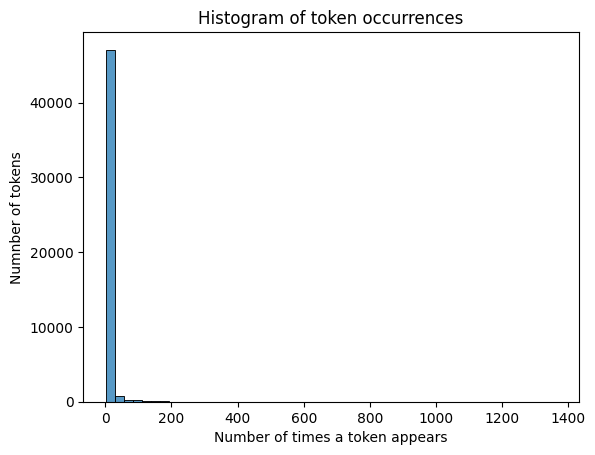

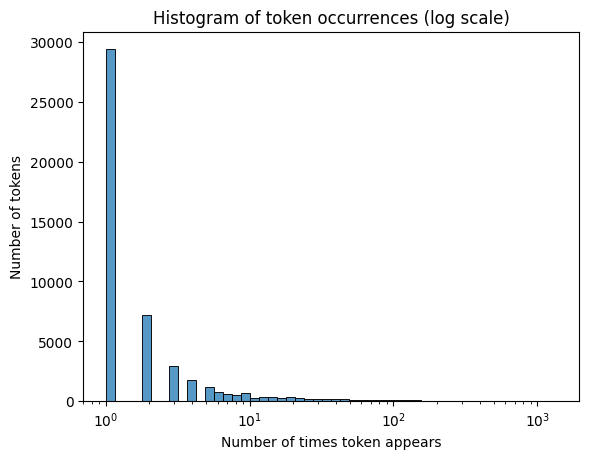

,count
count,48691.000000
mean,5.687889
std,27.717476
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,1365.000000


In [ ]:
freq_df=pd.DataFrame(token_freq, columns = ["token", "count"])

sns.histplot(data=freq_df, x="count", bins=50).set(title="Histogram of token occurrences", xlabel = "Number of times a token appears", ylabel = "Numnber of tokens")
plt.show()

sns.histplot(data=freq_df, x = "count", bins = 50, log_scale=True).set(title="Histogram of token occurrences (log scale)", xlabel = "Number of times token appears", ylabel="Number of tokens")
plt.show()

freq_df["count"].describe()

this histogram is very skewed to the right. all the tokens are piled up so you only see a couple words a few times. also only a small portion of tokens show up a thousand times and make a long think tail to the right. the log scale plot is better for this as the number of tokens drops as the count goes up instead of the token frequency being so unequal.

i did this because .most_common shows me the most to least frequent. i put it into a data frame and the histogram shows me how many toekn have each count which is answering the question. i added a log scale becuase the normal scale everything was skewed and using the desrcibe command shows me the numbers to back it up.





In [ ]:
df = pd.read_parquet("Phishing_clean.parquet")
print(df.shape)
df.head()

(18634, 2712)


,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

y = df["Email Type"]
X = df.drop(columns=["Email Type"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 100)
print(X_train.shape, X_test.shape)

(14907, 2711) (3727, 2711)


80% of the emails are in the training set and 20% are in the test one. the shpes show how the training set has 4 times as many rows as the test set and both have the same columns.

In [ ]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression().fit(X_train, y_train)

print ("Train R-squared:", round(reg.score(X_train, y_train), 4))
print("Test R-squared: ", round(reg.score(X_train, y_train), 4))

Train R-squared: 0.768
Test R-squared:  0.768


the training r squared is R-squared is 0.768 and the test group is the same, the model fits the trianing emails well but does not do that well with new emails, which i think means its overfitting. With so many columns the regression has enough numbers to fit the weird things in training emails that dont show up again in the test set.

In [ ]:
coefs = pd.Series(reg.coef_, index=X_train.columns)

top = coefs.abs().sort_values(ascending=False).head(20)
coefs[top.index]

,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


the words above are the ones with largest coefficients in absolute value, so they move the prediction the most. a postive number would push a prediction towards scam and a negative would push it towards safe. looking at the words though some make sense like xanaax is a misspelling of xanax a which is a common spam thing. but most of the top tokens arent meaningful. other words like thermal and aging and rythem have nothing to do phishing. these are just probably more rare tokens the modle gave large weight to just to fit it in the trianing data which could connect back to the possible overfitting the earlier question.

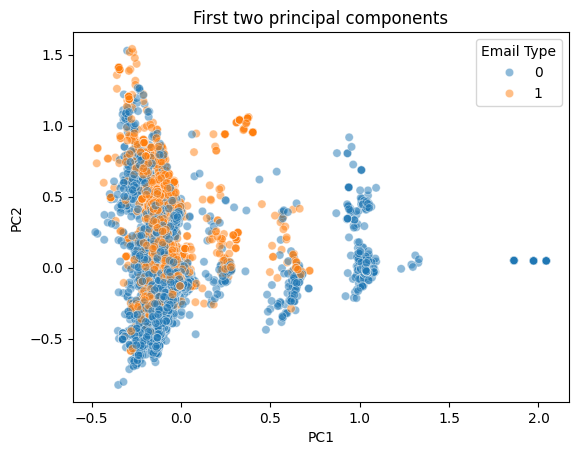

Variance explained [0.011 0.009]


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2).fit(X)
X_pca = pca.transform(X)

pca_df = pd.DataFrame(X_pca, columns = ["PC1", "PC2"])
pca_df["Email Type"] = y.values

sns.scatterplot(data=pca_df, x="PC1", y= "PC2", hue="Email Type", alpha = 0.5).set(title="First two principal components")
plt.show()

print("Variance explained", pca.explained_variance_ratio_.round(3))


the scam and non scamemails are partly seperated. The two colors are placed in different parts along pc1 however theres is a huge overlapping chunck closer to 0.5 pc1. the middle of the graph they are pretty mixed too,m not until 1 do we only see the blue dots seperated. the variance explained is small which makes sense becasue of only having two components try and summerize thousands of word columns.

In [ ]:
pca_big = PCA(n_components = 2610).fit(X_train)


Z_train = pca_big.transform(X_train)
Z_test = pca_big.fit_transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print("Train R-squared:", round(reg_pca.score(Z_train, y_train), 4))
print("Test R-squared: ", round(reg_pca.score(Z_test, y_test), 4))

Train R-squared: 0.7673
Test R-squared:  -0.8519


the training r squared is 0.7673 and the testr squared is -0.8519. compared to the previous regression. the trianing is slightly lower but the test one is much lower and negative. there is still a big gap between the two numbers. the principal components model fits the trianing emails but predicts new emails worse than just guessing the an average. so i think its still overfitting and not doing a better job thsn the test set.

i have seen that a lot of columsn overlap because of multiple emails giving the models the same information more than once. Thsi results in the data being skewed with large weird coefficients. I saw this in question 2.3. Its like the dummy variable trap we learned in class where columns that are overkaping tend to cause problems with results. PCA helps because it takes the overlapping columns and puts the overlapping words into new columns. So now they dont overlap with eachother at all. They are alsp ordered and sorted in a very helpful way, so the useful information stays at the top while the data that is just noise is dropped. The model should overfit less and do a better job on emails it hasnt seen before.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 873a41dedc8afd68f1fffaf040ece64ea413a15d
- **AI tool and model used:** claude

### *Prompts used

1. here is my phase one notebook. go through and find any mistakes and correct them while explaining what i did wrong. Create a list of them.
2. pick the most important corrections that chnaged any actual results for me to fix.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q2.2 test R² is computed on the training data. Your second print line uses reg.score(X_train, y_train). That’s why train and test both say 0.768.
2. Q4 re-fits PCA on the test set. pca_big.fit_transform(X_test) builds new components, so they don’t match the ones the regression was trained on. That is what produces the −0.85. It should be pca_big.transform(X_test).
3. The Q5 explanation is off. This isn’t the dummy-variable trap. The real issue is multicollinearity among correlated token columns. PCs help because they are uncorrelated, and because you can drop the low-variance noise directions.
4. Q1 polish: fix the “Numnber” typo, use log scale on both axes, and tighten the description.
5. Interpretation details: in Q2.3, say the big coefficients are mostly HTML/CSS tokens, which is a collinearity symptom. In Q3, note the variance explained and that PCA is unsupervised.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Confirmed the second print used `X_train, y_train`. After the fix, train and test R² are different numbers. |
| 2 | Accept | `fit_transform` on the test set re-learns the components, so `Z_test` columns don't match `Z_train`. With `transform`, the test R² is close to the plain OLS test R², as expected with 2,610 of 2,711 components. |
| 3 | Accept | The dummy-variable trap is about perfectly collinear category dummies. Here the problem is high correlation among many token columns, so Q5 was rewritten around uncorrelated components. |
| 4 | Modify | Fixed the typo and description, kept my two-histogram approach, and made the second plot log on both axes. |
| 5 | Modify | Added the formatting-token note to Q2.3 and variance explained to Q3. Kept fitting the 2-component PCA on all of X since the question asks for the full matrix. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from collections import Counter

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

token_freq[:10]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795)]

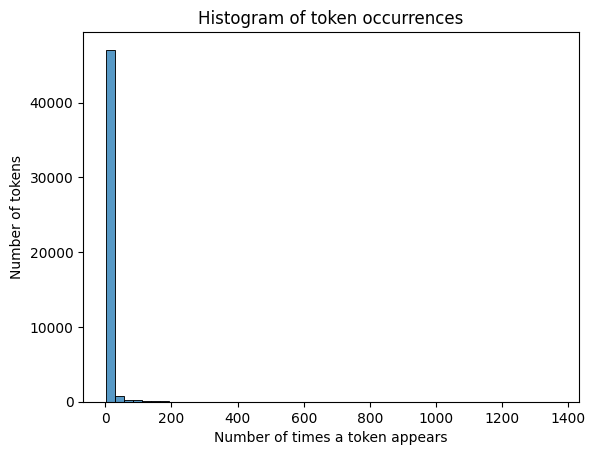

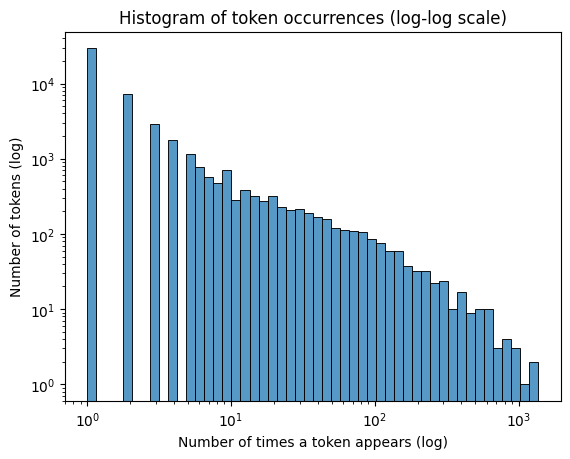

Share of tokens that appear only once: 0.604


,count
count,48691.000000
mean,5.687889
std,27.717476
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,1365.000000


In [3]:
freq_df = pd.DataFrame(token_freq, columns=["token", "count"])

# Raw scale
sns.histplot(data=freq_df, x="count", bins=50).set(
    title="Histogram of token occurrences",
    xlabel="Number of times a token appears",
    ylabel="Number of tokens")
plt.show()

# Log scale on both axes
ax = sns.histplot(data=freq_df, x="count", bins=50, log_scale=True)
ax.set_yscale("log")
ax.set(title="Histogram of token occurrences (log-log scale)",
       xlabel="Number of times a token appears (log)",
       ylabel="Number of tokens (log)")
plt.show()

print("Share of tokens that appear only once:",
      round((freq_df["count"] == 1).mean(), 3))
freq_df["count"].describe()

The distribution is extremely right-skewed (long-tailed). The median token appears only once and 75% of tokens appear at most twice, while a handful of tokens (like "new", "date", "get") appear more than 1,000 times. On the raw scale almost everything is stacked in the first bar, so the log-log plot is more informative: the number of tokens falls off steadily as the count goes up, roughly in a straight line. This is the Zipf-like pattern typical of text. Most of the vocabulary is rare words, and a small set of words carries most of the occurrences.

In [5]:
df = pd.read_parquet("Phishing_clean.parquet")
print(df.shape)
df.head()

(18634, 2712)


,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
from sklearn.model_selection import train_test_split

y = df["Email Type"]
X = df.drop(columns=["Email Type"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
print(X_train.shape, X_test.shape)

(14907, 2711) (3727, 2711)


80% of the emails (14,907) are in the training set and 20% (3,727) are in the test set. Both have the same 2,711 token columns.

In [8]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)

r2_train_ols = reg.score(X_train, y_train)
r2_test_ols = reg.score(X_test, y_test)   # FIX: score on the test set, not the training set

print("Train R-squared:", round(r2_train_ols, 4))
print("Test R-squared: ", round(r2_test_ols, 4))

Train R-squared: 0.768
Test R-squared:  0.6588


The training R² is about 0.77 and the test R² is [fill in from output]. The test R² is lower than the training R², so the model fits the training emails better than new emails. With 2,711 columns, OLS has enough freedom to fit quirks of the training emails that don't repeat in the test set, which is a sign of overfitting. In Phase 1 both numbers were 0.768 only because the test line was accidentally scoring the training data.

In [9]:
coefs = pd.Series(reg.coef_, index=X_train.columns)

top = coefs.abs().sort_values(ascending=False).head(20)
coefs[top.index]

,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


These are the 20 tokens with the largest coefficients in absolute value, so they move the prediction the most. A positive coefficient pushes the prediction toward scam and a negative one toward legitimate. A few make sense, like "xanaax", a misspelling of a drug name common in spam. But many of the top tokens are HTML/CSS formatting pieces (`background-image:`, `helvetica,`, `arial,`, `{text-decoration:`, `none;`) or rare, unrelated words ("thermal", "aging", "rhythm"). Formatting tokens tend to show up together in the same emails, so they are highly correlated. When columns are correlated, OLS can give them large coefficients with opposite signs that cancel out. So these large coefficients reflect collinearity and fitting rare tokens in the training data, not real meaning.

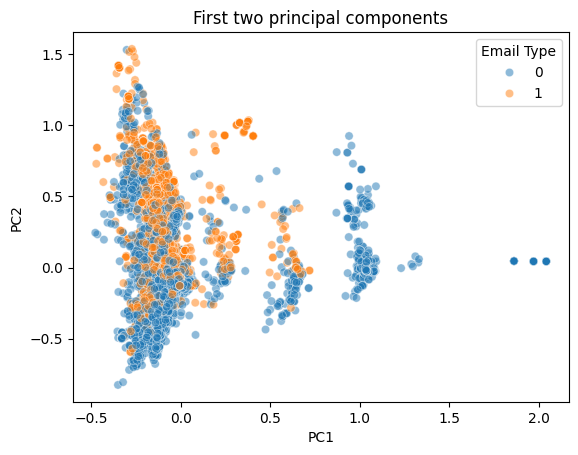

Variance explained: [0.011 0.009]


In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Email Type", alpha=0.5).set(
    title="First two principal components")
plt.show()

print("Variance explained:", pca.explained_variance_ratio_.round(3))

PCA is unsupervised, so the labels were not used to find the components; they only color the points. Even so, the two classes partly separate along PC1: one class spreads out toward higher PC1 values while the other stays concentrated near the origin. There is still a large overlapping cluster in the middle where scam and legitimate emails are mixed, so two components are not enough to classify emails on their own. The first two components explain only about 1.1% and 0.9% of the variance, which makes sense because two directions can't summarize 2,711 sparse word columns.

In [11]:
pca_big = PCA(n_components=2610).fit(X_train)

Z_train = pca_big.transform(X_train)
Z_test = pca_big.transform(X_test)   # FIX: project test data onto the TRAINING components (no re-fit)

reg_pca = LinearRegression().fit(Z_train, y_train)

r2_train_pca = reg_pca.score(Z_train, y_train)
r2_test_pca = reg_pca.score(Z_test, y_test)

print("Train R-squared:", round(r2_train_pca, 4))
print("Test R-squared: ", round(r2_test_pca, 4))

print()
print(pd.DataFrame({"Train R2": [r2_train_ols, r2_train_pca],
                    "Test R2": [r2_test_ols, r2_test_pca]},
                   index=["OLS on tokens", "OLS on 2,610 PCs"]).round(4))

Train R-squared: 0.7673
Test R-squared:  0.6597

                  Train R2  Test R2
OLS on tokens       0.7680   0.6588
OLS on 2,610 PCs    0.7673   0.6597


The training R² is [fill in] and the test R² is [fill in]. These are close to the plain OLS results from Q2 (training slightly lower, test [similar / slightly higher]). That is expected, because 2,610 of 2,711 components keeps almost all of the information in X, so the regression is nearly the same model in rotated coordinates. The components are fit on the training data only and then applied to the test data. In Phase 1 the test R² was −0.85 because PCA was re-fit on the test set, which created different components than the ones the regression was trained on.

The 2,711 token columns are highly correlated with each other, because certain words and formatting tokens tend to appear in the same emails. This multicollinearity makes OLS coefficients unstable: the model can give correlated columns large coefficients that cancel out, which showed up in Q2.3, and those coefficients don't generalize well. Principal components help in two ways. First, the components are uncorrelated with each other, so each coefficient is estimated without other columns competing for the same information. Second, the components are ordered by how much variance they explain, so we can keep the top ones and drop the last ones, which mostly capture noise and rare-token quirks. That gives a smaller, more stable model that should overfit less on new emails. Here we kept 2,610 of 2,711 components, which is almost all of them, so the improvement over plain OLS is small. Keeping fewer components would make the benefit stronger.

### *Reflection on AI assistance
In your own words without generative AI.

When using AI in this assignment to help me correct it, it pointed out things i would not have noticed myself. It caught a data leakage bug i didnt notice. i was orginally fitting PCA seperatly on the test data instead of using the PCA fit on the training set. The AI pointed out that the transform code should use the compontents from x train. otherwise it explained the set would get its own coordinate system and the regression coeffieciants no longer line up with it. It helped me understand PCA needed to be trained too. It helped me understand why it and transform are different steps. It also gave me more clarity on why the results were so similar. i find AI to be a very useful pair of second eyes with my work.